# 02 - Time-Series Exploration

Explore daily PM2.5 dynamics, autocorrelation, and stationarity. Interpolation below is used only for diagnostics, not as model input.


## Load and prepare the valid observations


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller

project_root = Path.cwd().resolve()
if not (project_root / "data" / "raw" / "combined_gee_pm25.csv").exists():
    project_root = project_root.parent
if not (project_root / "data" / "raw" / "combined_gee_pm25.csv").exists():
    raise FileNotFoundError("Could not locate data/raw/combined_gee_pm25.csv.")

sys.path.insert(0, str(project_root))
from src.config import FIGURES_DIR, RESULTS_DIR
from src.preprocessing import clean_pm25

raw_data = pd.read_csv(project_root / "data" / "raw" / "combined_gee_pm25.csv")
data = clean_pm25(raw_data)

daily_pm25 = (
    data.groupby("date")["pm25"]
    .mean()
    .sort_index()
    .asfreq("D")
)
daily_pm25_diagnostic = daily_pm25.interpolate(
    method="time",
    limit_area="inside",
)

print("Observed daily dates:", daily_pm25.notna().sum())
print("Calendar days:", len(daily_pm25))
print("Missing calendar dates:", daily_pm25.isna().sum())
print("Diagnostic series dates:", daily_pm25_diagnostic.notna().sum())


Observed daily dates: 2299
Calendar days: 3420
Missing calendar dates: 1121
Diagnostic series dates: 3420


## Monthly and annual patterns


In [2]:
monthly_summary = (
    data.set_index("date")["pm25"]
    .resample("ME")
    .agg(["mean", "median", "std", "count"])
)
annual_summary = (
    data.set_index("date")["pm25"]
    .resample("YE")
    .agg(["mean", "median", "std", "count"])
)

print("Monthly summary:")
display(monthly_summary.head(12))
print("Annual summary:")
display(annual_summary)

exploration_dir = RESULTS_DIR / "exploration"
exploration_dir.mkdir(parents=True, exist_ok=True)
monthly_summary.to_csv(exploration_dir / "timeseries_monthly_summary.csv")
annual_summary.to_csv(exploration_dir / "timeseries_annual_summary.csv")


Monthly summary:


,mean,median,std,count
date,,,,
2016-11-30,4.854167,2.675000,4.543929,4
2016-12-31,11.114897,10.200000,5.655116,107
2017-01-31,7.515675,6.183333,4.215305,24
2017-02-28,12.096893,10.864583,5.331851,95
2017-03-31,9.857475,7.818182,10.940029,164
2017-04-30,9.232362,7.100000,9.910862,206
2017-05-31,7.551486,6.428571,5.073475,215
2017-06-30,7.489942,6.285714,5.008540,395
2017-07-31,7.603972,6.475446,6.197072,284


Annual summary:


,mean,median,std,count
date,,,,
2016-12-31,10.889285,10.166667,5.723155,111
2017-12-31,9.460013,7.666667,7.746498,2116
2018-12-31,7.879574,7.018750,4.867492,252
2019-12-31,8.654724,6.718254,7.486113,1772
2020-12-31,7.554598,5.714286,8.078668,3247
2021-12-31,8.854864,6.800000,14.865300,4746
2022-12-31,9.619613,8.125000,12.382154,4954
2023-12-31,10.223157,9.000000,6.766311,5400
2024-12-31,9.612762,8.000000,9.754870,8688


## ACF, PACF, and stationarity checks


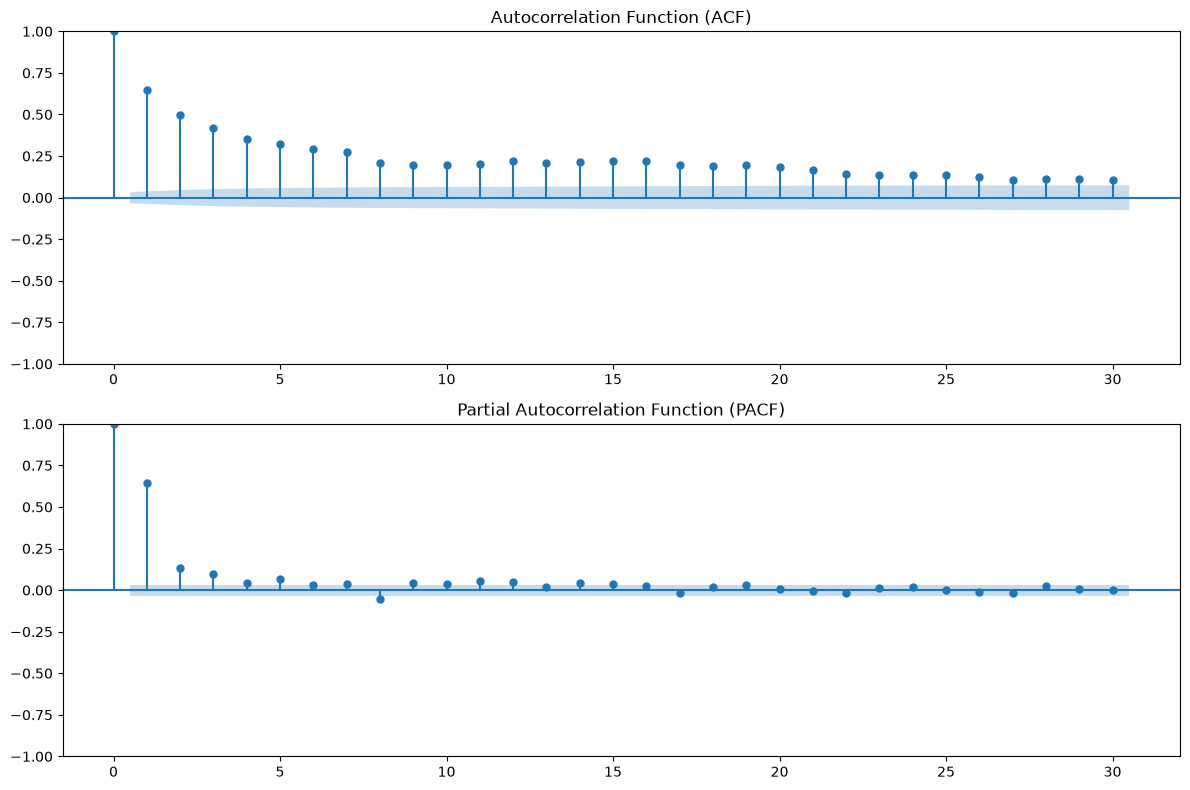

ADF statistic: -8.5929
ADF p-value: 0.0
Ljung-Box results:


C:\Users\Pc\AppData\Local\Temp\ipykernel_3040\2620964232.py:19: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series, autolag="AIC")


,lb_stat,lb_pvalue
7,4216.6199,0.0
14,5251.9342,0.0
30,6662.9737,0.0


In [3]:
series = daily_pm25_diagnostic.dropna()
if len(series) <= 61:
    raise ValueError("At least 62 daily observations are needed for 30-lag diagnostics.")

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(series, lags=30, ax=axes[0])
axes[0].set_title("Autocorrelation Function (ACF)")
plot_pacf(series, lags=30, method="ywm", ax=axes[1])
axes[1].set_title("Partial Autocorrelation Function (PACF)")
fig.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(
    FIGURES_DIR / "acf_pacf_timeseries.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

adf_result = adfuller(series, autolag="AIC")
ljung_box_result = acorr_ljungbox(series, lags=[7, 14, 30], return_df=True)
print("ADF statistic:", round(adf_result[0], 4))
print("ADF p-value:", round(adf_result[1], 6))
print("Ljung-Box results:")
display(ljung_box_result.round(4))

stationarity_summary = pd.DataFrame({
    "Metric": ["ADF statistic", "ADF p-value", "Used lags", "Observations"],
    "Value": [adf_result[0], adf_result[1], adf_result[2], adf_result[3]],
})
stationarity_summary.to_csv(
    exploration_dir / "timeseries_stationarity_tests.csv",
    index=False,
)
ljung_box_result.to_csv(exploration_dir / "timeseries_ljung_box.csv")
